# Laboratorium 3 - klasyfikator CIFAR-10 i filtracja zakłóceń

Część I realizuje przygotowanie z `DO_DOMU`, a część II zadania A-E z `NA_ZAJECIA`. Wszystkie wyniki powstają z tego samego zapisanego modelu i podziału danych. **Uwaga: w repozytorium nie ma generatora prowadzącego, dlatego część II jest eksperymentem demonstracyjnym z generatorem zastępczym.** Po otrzymaniu właściwego generatora trzeba ponownie wykonać część II i zaktualizować raport.

## 0. Pakiety, ziarno losowe i konfiguracja

Uruchom wszystkie komórki od początku. Pierwsza komórka sprawdza import wymaganych pakietów i wypisuje ich wersje. Jeżeli wagi już istnieją, zostaną wczytane bez ponownego treningu. Ścieżki działają przy uruchomieniu z katalogu `lab3` lub z katalogu głównego projektu.

In [1]:
import copy
import json
import platform
import random
from pathlib import Path

import jupyter_core
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sklearn
import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import CIFAR10
from sklearn.metrics import accuracy_score, f1_score

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
LAB_DIR = Path.cwd()
if (LAB_DIR / 'lab3' / 'Laboratorium_3_START_DOM.ipynb').is_file():
    LAB_DIR = LAB_DIR / 'lab3'
DATA = LAB_DIR / 'data'
CKPT = LAB_DIR / 'fourier_lab_model.pt'
SPLITS = LAB_DIR / 'cifar10_split_indices.npz'
METRICS = LAB_DIR / 'validation_metrics.json'
HISTORY = LAB_DIR / 'training_history.json'

versions = {
    'Python': platform.python_version(),
    'Jupyter core': jupyter_core.__version__,
    'numpy': np.__version__,
    'matplotlib': matplotlib.__version__,
    'scipy': scipy.__version__,
    'scikit-learn': sklearn.__version__,
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
}
for name, version in versions.items():
    print(f'{name}: {version}')
print('Urządzenie:', device)
print('Katalog laboratorium:', LAB_DIR)

Python: 3.12.0
Jupyter core: 5.7.2
numpy: 1.26.1
matplotlib: 3.8.1
scipy: 1.15.1
scikit-learn: 1.6.1
torch: 2.5.1+cu121
torchvision: 0.20.1+cu121
Urządzenie: cuda
Katalog laboratorium: c:\Users\mateu\Desktop\Studia\MRO\lab3


## 1. Dane i rozłączne podzbiory

Z oficjalnego treningu (50 000 obrazów) wybieramy 5000 do uczenia, 1000 do walidacji i 300 dodatkowych do późniejszej kalibracji. Z oficjalnego testu (10 000 obrazów) wybieramy 1000 obrazów do końcowej oceny na zajęciach. Test nie służy do uczenia ani wyboru epoki.

Podział używa tego samego ziarna i kolejności losowania co pierwotny notebook. Indeksy zapisujemy w `cifar10_split_indices.npz`; kolejne uruchomienia wczytują ten plik. Indeks z oficjalnego testu i taki sam numer z oficjalnego treningu oznaczają różne obrazy.

In [2]:
train_full = CIFAR10(DATA, train=True, download=True)
test_full = CIFAR10(DATA, train=False, download=True)
assert len(train_full) == 50000 and len(test_full) == 10000

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(train_full))
expected_splits = {
    'train_idx': idx[:5000],
    'val_idx': idx[5000:6000],
    'calib_idx': idx[6000:6300],
    'test_idx': rng.permutation(len(test_full))[:1000],
}
if SPLITS.exists():
    with np.load(SPLITS, allow_pickle=False) as saved:
        assert int(saved['seed'].item()) == SEED, 'Inne ziarno w zapisanym podziale.'
        for name, expected in expected_splits.items():
            np.testing.assert_array_equal(saved[name], expected)
        train_idx = saved['train_idx'].copy()
        val_idx = saved['val_idx'].copy()
        calib_idx = saved['calib_idx'].copy()
        test_idx = saved['test_idx'].copy()
    print('Wczytano zapisane indeksy:', SPLITS.name)
else:
    train_idx = expected_splits['train_idx']
    val_idx = expected_splits['val_idx']
    calib_idx = expected_splits['calib_idx']
    test_idx = expected_splits['test_idx']

for ids, size, limit in [
    (train_idx, 5000, len(train_full)),
    (val_idx, 1000, len(train_full)),
    (calib_idx, 300, len(train_full)),
    (test_idx, 1000, len(test_full)),
]:
    assert len(ids) == size and len(np.unique(ids)) == size
    assert np.all((ids >= 0) & (ids < limit))
assert len(np.unique(np.concatenate([train_idx, val_idx, calib_idx]))) == 6300
# Rozłączność ze zbiorem testowym wynika z innego oficjalnego źródła.
if not SPLITS.exists():
    np.savez_compressed(SPLITS, seed=np.array(SEED), **expected_splits)
    print('Zapisano indeksy:', SPLITS.name)

def to_array(ds, ids):
    x = np.asarray(ds.data[ids], dtype=np.float32) / 255.0
    y = np.asarray(ds.targets, dtype=np.int64)[ids]
    return x, y

Xtr, ytr = to_array(train_full, train_idx)
Xval, yval = to_array(train_full, val_idx)
Xcal, ycal = to_array(train_full, calib_idx)
Xtest, ytest = to_array(test_full, test_idx)
classes = train_full.classes
assert train_full.classes == test_full.classes
print('train / val / calib / test:', len(Xtr), len(Xval), len(Xcal), len(Xtest))
print('Sprawdzono liczebności, zakresy indeksów i rozłączność podzbiorów.')

Files already downloaded and verified
Files already downloaded and verified
Wczytano zapisane indeksy: cifar10_split_indices.npz
train / val / calib / test: 5000 1000 300 1000
Sprawdzono liczebności, zakresy indeksów i rozłączność podzbiorów.


## 2. Architektura CNN i normalizacja

Model ma trzy warstwy konwolucyjne i dwie warstwy liniowe. **Normalizacja użyta przez zapisany model:** RGB `uint8` dzielimy przez 255, otrzymując `float32` w zakresie [0, 1]. Nie odejmujemy średniej ani nie dzielimy przez odchylenie standardowe. Przed podaniem do sieci zmieniamy układ HWC na CHW (3 × 32 × 32). Takie samo przetwarzanie należy zachować na zajęciach. Trening korzysta wyłącznie z czystych obrazów, bez zakłóceń i augmentacji.

In [3]:
class ArrayDataset(Dataset):
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return torch.from_numpy(self.x[i].transpose(2, 0, 1).copy()), int(self.y[i])


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d((2, 2)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 2 * 2, 128), nn.ReLU(),
            nn.Dropout(0.25), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def evaluate(model, x, y, batch_size=256):
    loader = DataLoader(ArrayDataset(x, y), batch_size=batch_size, shuffle=False)
    model.eval()
    preds = []
    with torch.inference_mode():
        for xb, _ in loader:
            preds.extend(model(xb.to(device)).argmax(1).cpu().tolist())
    preds = np.asarray(preds, dtype=np.int64)
    metrics = {
        'accuracy': float(accuracy_score(y, preds)),
        'f1_macro': float(f1_score(y, preds, labels=np.arange(10),
                                   average='macro', zero_division=0)),
    }
    return metrics, preds

## 3. Trening i wybór epoki na podstawie walidacji

Przy braku wag uczymy model przez maksymalnie 8 epok i zapisujemy stan z **największą accuracy na walidacji** (przy remisie zostaje wcześniejsza epoka). Zbiór testowy i dodatkowy nie uczestniczą w treningu ani wyborze modelu. Dla nowego treningu historia i numer wybranej epoki trafiają do `training_history.json`.

Jeżeli `fourier_lab_model.pt` już istnieje, zachowujemy te wagi i wczytujemy model. Sam plik wag nie zawiera historii treningu, więc bez osobnego zapisu nie można ustalić, w której epoce powstały istniejące wagi.

In [4]:
model = SmallCNN().to(device)
training_info = None
if CKPT.exists():
    model.load_state_dict(torch.load(CKPT, map_location=device, weights_only=True), strict=True)
    print('Wczytano istniejące wagi:', CKPT.name)
    if HISTORY.exists():
        training_info = json.loads(HISTORY.read_text(encoding='utf-8'))
        print('Zapisana najlepsza epoka:', training_info['best_epoch'])
    else:
        print('Brak zapisanej historii wcześniejszego treningu; numer epoki jest nieznany.')
else:
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(ArrayDataset(Xtr, ytr), batch_size=128, shuffle=True,
                        generator=generator)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    best_acc, best_state, best_epoch = -1.0, None, None
    history = []
    for epoch in range(1, 9):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * len(yb)
        val, _ = evaluate(model, Xval, yval)
        train_loss = total_loss / len(Xtr)
        history.append({'epoch': epoch, 'train_loss': train_loss, **val})
        print(f'Epoka {epoch:2d} | loss {train_loss:.3f} | '
              f'val accuracy {val["accuracy"]:.3f} | val F1-macro {val["f1_macro"]:.3f}')
        if val['accuracy'] > best_acc:
            best_acc = val['accuracy']
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
    model.load_state_dict(best_state)
    torch.save(model.state_dict(), CKPT)
    training_info = {
        'seed': SEED, 'selection_metric': 'validation_accuracy',
        'best_epoch': best_epoch, 'max_epochs': 8, 'history': history,
    }
    HISTORY.write_text(json.dumps(training_info, ensure_ascii=False, indent=2) + '\n',
                       encoding='utf-8')
    print('Zapisano:', CKPT.name, '| Najlepsza epoka:', best_epoch)
model.eval();model.eval();

Wczytano istniejące wagi: fourier_lab_model.pt
Brak zapisanej historii wcześniejszego treningu; numer epoki jest nieznany.


## 4. Sprawdzenie odtworzenia z zapisanych wag

Tworzymy nową instancję architektury i ładujemy do niej wyłącznie zapisany `state_dict`. Sprawdzamy zgodność parametrów oraz predykcji i metryk na całej walidacji. Dalej używamy odtworzonej instancji w trybie `eval()` (Dropout wyłączony).

In [5]:
metrics_before, preds_before = evaluate(model, Xval, yval)
restored_model = SmallCNN().to(device)
restored_model.load_state_dict(
    torch.load(CKPT, map_location=device, weights_only=True), strict=True,
)
restored_model.eval()
for name, value in model.state_dict().items():
    torch.testing.assert_close(value, restored_model.state_dict()[name], rtol=0, atol=0)
val_metrics, val_preds = evaluate(restored_model, Xval, yval)
np.testing.assert_array_equal(preds_before, val_preds)
assert metrics_before == val_metrics
model = restored_model
reload_verified = True
print('Odtworzenie modelu: OK.')
print('Parametry oraz predykcje dla wszystkich 1000 obrazów walidacyjnych są zgodne.')

Odtworzenie modelu: OK.
Parametry oraz predykcje dla wszystkich 1000 obrazów walidacyjnych są zgodne.


## 5. Wyniki walidacji i ich zapis

Accuracy to udział poprawnych klasyfikacji, a F1-macro to średnia F1 dla wszystkich 10 klas z jednakową wagą każdej klasy. Poniższe wyniki dotyczą wyłącznie 1000 obrazów walidacyjnych. Zapisujemy je także w `validation_metrics.json` wraz ze sposobem normalizacji, ziarnem i informacją o odtworzeniu modelu.

In [6]:
n_correct = int(np.count_nonzero(val_preds == yval))
n_incorrect = int(np.count_nonzero(val_preds != yval))
validation_report = {
    'dataset': 'CIFAR-10',
    'subset': 'validation from official training set',
    'n_samples': int(len(yval)),
    **val_metrics,
    'n_correct': n_correct,
    'n_incorrect': n_incorrect,
    'seed': SEED,
    'split_file': SPLITS.name,
    'checkpoint': CKPT.name,
    'architecture': 'SmallCNN (definition in notebook)',
    'normalization': 'RGB uint8 -> float32 / 255.0; HWC -> CHW; no standardization',
    'reload_verified': reload_verified,
    'best_epoch': training_info['best_epoch'] if training_info else None,
    'versions': versions,
}
METRICS.write_text(json.dumps(validation_report, ensure_ascii=False, indent=2) + '\n',
                   encoding='utf-8')
print(f'Accuracy na walidacji: {val_metrics["accuracy"]:.4f} '
      f'({100 * val_metrics["accuracy"]:.2f}%)')
print(f'F1-macro na walidacji: {val_metrics["f1_macro"]:.4f}')
print(f'Poprawne: {n_correct}; błędne: {n_incorrect}; razem: {len(yval)}')
print('Zapisano wyniki:', METRICS.name)

Accuracy na walidacji: 0.3670 (36.70%)
F1-macro na walidacji: 0.3556
Poprawne: 367; błędne: 633; razem: 1000
Zapisano wyniki: validation_metrics.json


## 6. Trzy poprawne i trzy błędne klasyfikacje

Pokazujemy po trzy pierwsze przykłady obu rodzajów z walidacji. Każdy podpis zawiera prawdziwą klasę, predykcję i indeks obrazu w oficjalnym zbiorze treningowym. Do wizualizacji używamy obrazów po skalowaniu do [0, 1].

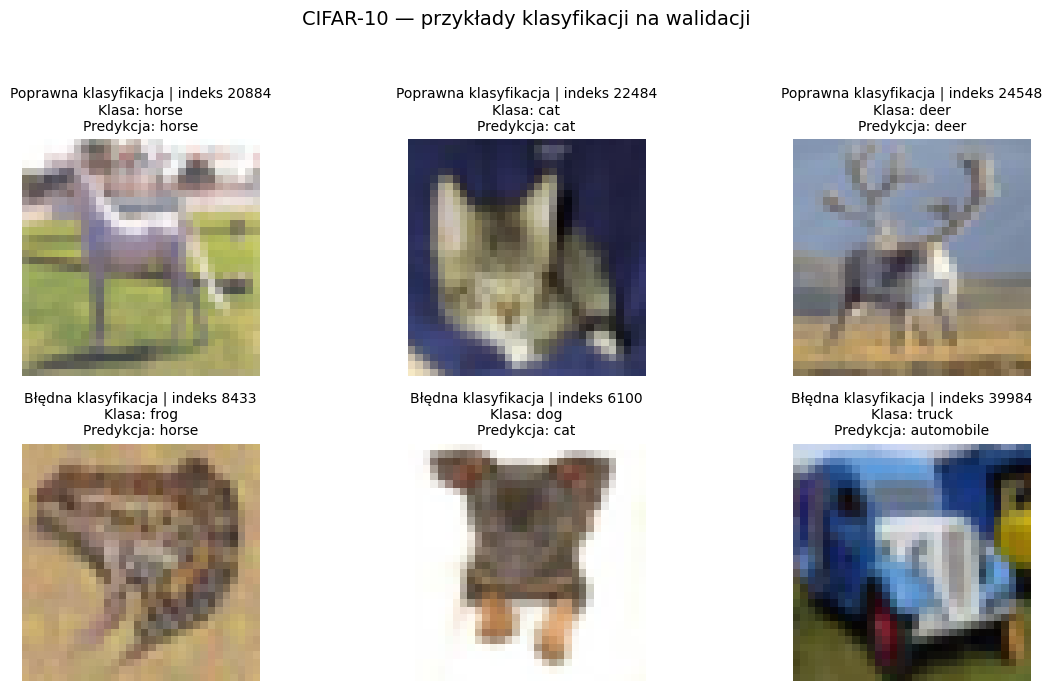

In [7]:
correct_ids = np.flatnonzero(val_preds == yval)
incorrect_ids = np.flatnonzero(val_preds != yval)
assert len(correct_ids) >= 3 and len(incorrect_ids) >= 3, (
    'Potrzeba co najmniej 3 poprawnych i 3 błędnych predykcji na walidacji.'
)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, (label, ids) in enumerate([
    ('Poprawna klasyfikacja', correct_ids[:3]),
    ('Błędna klasyfikacja', incorrect_ids[:3]),
]):
    for col, i in enumerate(ids):
        ax = axes[row, col]
        ax.imshow(Xval[i])
        ax.set_title(
            f'{label} | indeks {int(val_idx[i])}\n'
            f'Klasa: {classes[int(yval[i])]}\n'
            f'Predykcja: {classes[int(val_preds[i])]}',
            fontsize=10,
        )
        ax.axis('off')
fig.suptitle('CIFAR-10 — przykłady klasyfikacji na walidacji', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## Koniec przygotowania

Zachowujemy architekturę, normalizację RGB / 255, istniejące wagi i zapisane indeksy. Poniżej zaczyna się część wykonywana na zajęciach; nie uczymy ponownie sieci.

# Część II - Znajdź zakłócenie i uratuj klasyfikację

Sprawdzamy hipotezę, czy usunięcie wykrytej pary częstotliwości pomaga bardziej niż filtr Gaussa. Nie zakładamy poprawy z góry. Model i podział pozostają niezmienione. Detekcja i wybór parametrów wykorzystują wyłącznie 300 obrazów kalibracyjnych; etykiety kalibracyjne nie są potrzebne. Ocena końcowa dotyczy tych samych 1000 obrazów testowych we wszystkich wariantach.

**Status generatora:** używamy `generator_demonstracyjny.py`, bo generator prowadzącego nie został dostarczony. Generator tworzy zakłócenie zgodne z podanym wzorem, ze wspólną amplitudą i częstotliwością oraz osobną fazą dla każdego obrazu. Wykrywanie nie odczytuje jego parametrów. Nie jest to w pełni ślepa próba z generatorem prowadzącego; wyników nie należy przedstawiać jako takiej próby.

In [8]:
import csv
import hashlib
import sys
from IPython.display import Markdown, display
from scipy.ndimage import gaussian_filter

assert CKPT.exists() and SPLITS.exists(), 'Najpierw wykonaj przygotowanie.'
assert len(Xcal) == 300 and len(Xtest) == 1000
model.eval()
checkpoint_hash_before = hashlib.sha256(CKPT.read_bytes()).hexdigest()
RESULTS = LAB_DIR / 'wyniki_lab3'
RESULTS.mkdir(exist_ok=True)
GENERATOR_SOURCE = 'demonstracyjny; brak generatora prowadzącego'
NOISE_SEED_CAL = SEED + 100
NOISE_SEED_TEST = SEED + 200
# Siatki ustalone przed oceną testową; kryterium: MSE na kalibracji.
NOTCH_RADII = (0, 1, 2)
GAUSSIAN_SIGMAS = (0.3, 0.5, 0.75, 1.0, 1.25, 1.5)
EXAMPLE_INDEX = 0  # stały przykład, bez wybierania według wyniku modelu
print('Wagi zamrożone. Generator:', GENERATOR_SOURCE)
print('SHA-256 wag:', checkpoint_hash_before)

Wagi zamrożone. Generator: demonstracyjny; brak generatora prowadzącego
SHA-256 wag: 9e88cb2438ac3493814b3949a0e7f9502ea01df4ab9275b28928517243160bf8


## A. Wygenerowanie zakłóceń i obejrzenie przykładów

Nie obcinamy danych do [0, 1] przed FFT, filtracją, obliczeniem MSE ani klasyfikacją. `np.clip` występuje wyłącznie w `imshow`. Dla czytelności pokazujemy trzy pierwsze obrazy kalibracyjne przed i po zakłóceniu. Accuracy czystego i zakłóconego testu obliczymy w E, dopiero po zamrożeniu parametrów filtrów.

Zakres kalibracji po zakłóceniu: [-0.250, 1.250]
Wartości poza [0, 1] pozostają w obliczeniach.


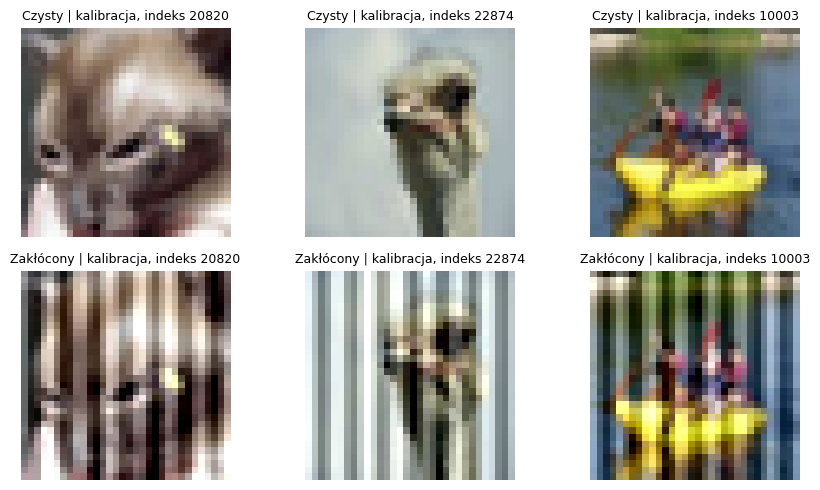

In [9]:
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
from generator_demonstracyjny import generate_interference

# Tę funkcję wywołującą należy zastąpić generatorem prowadzącego.
Xcal_noisy = generate_interference(Xcal, seed=NOISE_SEED_CAL)
Xtest_noisy = generate_interference(Xtest, seed=NOISE_SEED_TEST)
assert Xcal_noisy.shape == Xcal.shape and Xtest_noisy.shape == Xtest.shape
assert np.isfinite(Xcal_noisy).all() and np.isfinite(Xtest_noisy).all()
print(f'Zakres kalibracji po zakłóceniu: [{Xcal_noisy.min():.3f}, {Xcal_noisy.max():.3f}]')
print('Wartości poza [0, 1] pozostają w obliczeniach.')
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for col in range(3):
    for row, (label, images) in enumerate([('Czysty', Xcal), ('Zakłócony', Xcal_noisy)]):
        axes[row, col].imshow(np.clip(images[col], 0, 1))
        axes[row, col].set_title(f'{label} | kalibracja, indeks {int(calib_idx[col])}', fontsize=9)
        axes[row, col].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'trzy_przyklady.png', dpi=180, bbox_inches='tight')
plt.show()

## B. Amplituda, faza i odwrotna FFT

Do wykresu pojedynczego obrazu używamy średniej kanałów RGB, co daje jeden czytelny obraz w skali szarości. FFT i filtracja całych zbiorów w dalszych sekcjach działają osobno na każdym kanale RGB. Amplituda opisuje udział składowych, a faza ich położenie względem siebie. Ustawienie faz na zero zachowuje amplitudy, lecz zwykle niszczy układ obiektów. Porównujemy błąd pełnej rekonstrukcji z błędem rekonstrukcji po wyzerowaniu faz.

FFT -> IFFT: maks. błąd 2.220e-16; MSE 1.742e-33.
Rekonstrukcja bez fazy: MSE 0.121936.


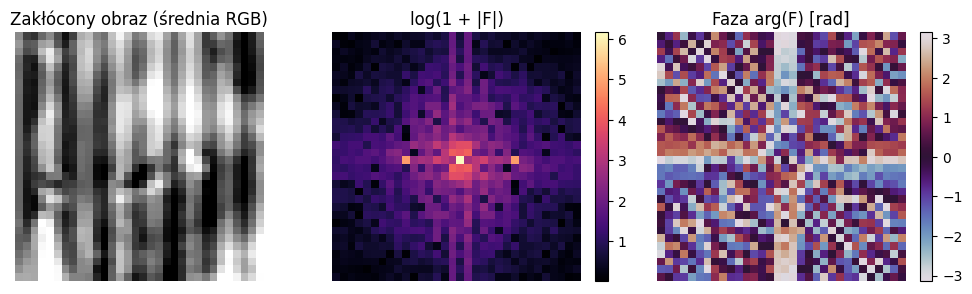

In [10]:
gray = Xcal_noisy[0].mean(axis=-1).astype(np.float64)
F = np.fft.fft2(gray)
F_shift = np.fft.fftshift(F)
reconstructed = np.fft.ifft2(F)
without_phase = np.fft.ifft2(np.abs(F)).real
fft_max_error = float(np.max(np.abs(reconstructed.real - gray)))
fft_mse = float(np.mean((reconstructed.real - gray) ** 2))
fft_imag_error = float(np.max(np.abs(reconstructed.imag)))
no_phase_mse = float(np.mean((without_phase - gray) ** 2))
assert fft_max_error < 1e-12 and fft_imag_error < 1e-12
print(f'FFT -> IFFT: maks. błąd {fft_max_error:.3e}; MSE {fft_mse:.3e}.')
print(f'Rekonstrukcja bez fazy: MSE {no_phase_mse:.6f}.')
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(np.clip(gray, 0, 1), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Zakłócony obraz (średnia RGB)')
im1 = axes[1].imshow(np.log1p(np.abs(F_shift)), cmap='magma')
axes[1].set_title('log(1 + |F|)')
fig.colorbar(im1, ax=axes[1], fraction=0.046)
im2 = axes[2].imshow(np.angle(F_shift), cmap='twilight', vmin=-np.pi, vmax=np.pi)
axes[2].set_title('Faza arg(F) [rad]')
fig.colorbar(im2, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'fft_obraz.png', dpi=180, bbox_inches='tight')
plt.show()

## C. Uśrednione widmo mocy i własne detect_pair(power)

Obliczamy FFT po wymiarach przestrzennych, następnie średnią |F|² po 300 obrazach i trzech kanałach. Kanały traktujemy równorzędnie. Po `fftshift` DC leży w (16, 16). Detektor pomija koło o promieniu 3 wokół DC i pary złożone z jednego punktu samosprzężonego. Wybiera parę o największej średniej mocy obu symetrycznych punktów. Współrzędne zapisujemy jako **(wiersz, kolumna), indeksowanie od zera w przesuniętym widmie**.

Losowe fazy mogą znosić się w średniej zespolonych F. Moc |F|² jest nieujemna i niezależna od fazy sinusoidy, więc wspólne częstotliwości pozostają widoczne. Piki porównujemy również z widmem czystej kalibracji: duży przyrost mocy po dodaniu zakłócenia jest dowodem mocniejszym niż sam jasny punkt.

Pik (16, 9): moc czysta 49.205, zakłócona 16401.697, iloraz 333.3x.
Pik (16, 23): moc czysta 49.205, zakłócona 16401.697, iloraz 333.3x.


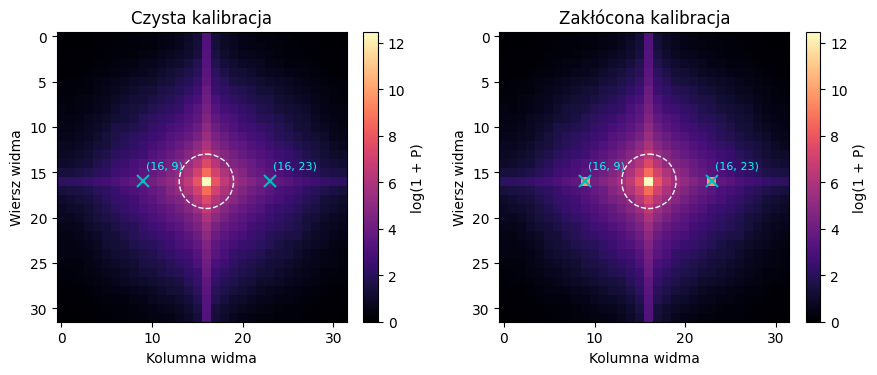

In [11]:
def mean_power(images):
    spectra = np.fft.fft2(images, axes=(1, 2))
    shifted = np.fft.fftshift(spectra, axes=(1, 2))
    return np.mean(np.abs(shifted) ** 2, axis=(0, 3))


def conjugate_point(point, shape):
    return tuple((2 * (n // 2) - i) % n for i, n in zip(point, shape))


def detect_pair(power):
    """Zwróć dwie różne symetryczne współrzędne maksimum poza centrum."""
    power = np.asarray(power, dtype=np.float64)
    if power.ndim != 2 or min(power.shape) < 9:
        raise ValueError('Oczekiwano dwuwymiarowego widma co najmniej 9 x 9.')
    if not np.isfinite(power).all() or np.any(power < 0):
        raise ValueError('Moc musi być skończona i nieujemna.')
    h, w = power.shape
    rows, cols = np.indices((h, w))
    opposite_rows = (2 * (h // 2) - rows) % h
    opposite_cols = (2 * (w // 2) - cols) % w
    score = 0.5 * (power + power[opposite_rows, opposite_cols])
    outside_center = (rows - h // 2) ** 2 + (cols - w // 2) ** 2 > 3 ** 2
    different_point = (rows != opposite_rows) | (cols != opposite_cols)
    score = np.where(outside_center & different_point, score, -np.inf)
    if not np.isfinite(score).any():
        raise ValueError('Brak dopuszczalnej pary poza centrum.')
    first = tuple(int(i) for i in np.unravel_index(np.argmax(score), power.shape))
    second = conjugate_point(first, power.shape)
    return tuple(sorted((first, second)))


# Kontrola algorytmu na sztucznym widmie; nie używa częstotliwości generatora.
synthetic_power = np.ones((32, 32))
synthetic_power[16, 16] = 1e9  # najsilniejszy DC ma zostać pominięty
synthetic_power[10, 7] = synthetic_power[22, 25] = 1000
assert detect_pair(synthetic_power) == ((10, 7), (22, 25))
power_clean = mean_power(Xcal)
power_noisy = mean_power(Xcal_noisy)
detected_pair = detect_pair(power_noisy)
assert conjugate_point(detected_pair[0], power_noisy.shape) == detected_pair[1]
peak_evidence = []
for point in detected_pair:
    clean_value = float(power_clean[point])
    noisy_value = float(power_noisy[point])
    ratio = noisy_value / max(clean_value, np.finfo(float).tiny)
    peak_evidence.append({'row': point[0], 'column': point[1],
                          'power_clean': clean_value, 'power_noisy': noisy_value,
                          'power_ratio': ratio})
    print(f'Pik {point}: moc czysta {clean_value:.3f}, '
          f'zakłócona {noisy_value:.3f}, iloraz {ratio:.1f}x.')
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
vmax = float(np.log1p(power_noisy).max())
for ax, label, power in zip(axes, ['Czysta kalibracja', 'Zakłócona kalibracja'],
                            [power_clean, power_noisy]):
    im = ax.imshow(np.log1p(power), cmap='magma', vmin=0, vmax=vmax)
    for row, col in detected_pair:
        ax.plot(col, row, 'cx', markersize=9, markeredgewidth=1.5)
        ax.annotate(f'({row}, {col})', (col, row), xytext=(2, 9),
                    textcoords='offset points', color='cyan', fontsize=8)
    ax.add_patch(plt.Circle((16, 16), 3, fill=False, color='white', linestyle='--'))
    ax.set_title(label)
    ax.set_xlabel('Kolumna widma')
    ax.set_ylabel('Wiersz widma')
    fig.colorbar(im, ax=ax, fraction=0.046, label='log(1 + P)')
fig.tight_layout()
fig.savefig(RESULTS / 'widmo_piki.png', dpi=180, bbox_inches='tight')
plt.show()

## D. Filtr notch i przestrzenny filtr Gaussa

Notch zeruje współczynniki w jednakowych, kołowych otoczeniach obu pików. Pozostałe współczynniki zachowuje bez zmiany amplitudy i fazy. Odległości na siatce widma liczymy z zawijaniem; maska pozostaje sprzężenie symetryczna. Kontrolujemy część urojoną odwrotnej transformacji.

Promień notch wybieramy z {0, 1, 2}, a sigma Gaussa z {0,3; 0,5; 0,75; 1; 1,25; 1,5} piksela. Kryterium obu wyborów to najmniejsze MSE względem **czystej kalibracji**. Nie używamy etykiet kalibracyjnych ani żadnych metryk testowych. Jest to kryterium rekonstrukcji, więc nie gwarantuje największej accuracy. Gauss działa tylko w przestrzeni obrazu, osobno dla każdego kanału i obrazu.

Wybór parametrów wyłącznie na kalibracji:
notch | parametr    0 | MSE 0.000094
notch | parametr    1 | MSE 0.000394
notch | parametr    2 | MSE 0.000972
gauss | parametr  0.3 | MSE 0.030877
gauss | parametr  0.5 | MSE 0.022065
gauss | parametr 0.75 | MSE 0.013159
gauss | parametr  1.0 | MSE 0.008640
gauss | parametr 1.25 | MSE 0.007014
gauss | parametr  1.5 | MSE 0.007182
Zamrożono: notch r=0, sigma Gaussa=1.25.
Usuwane współczynniki na kanał: 2


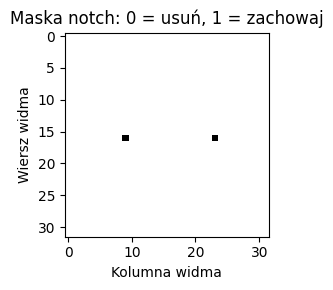

In [12]:
def mse(images, reference):
    return float(np.mean((images.astype(np.float64) - reference) ** 2))


def make_notch_mask(shape, pair, radius):
    if radius < 0:
        raise ValueError('Promień musi być nieujemny.')
    h, w = shape
    rows, cols = np.indices(shape)
    mask = np.ones(shape, dtype=np.float64)
    for row, col in pair:
        dr = np.abs(rows - row)
        dc = np.abs(cols - col)
        dr = np.minimum(dr, h - dr)
        dc = np.minimum(dc, w - dc)
        mask[dr ** 2 + dc ** 2 <= radius ** 2] = 0
    opposite_rows = (2 * (h // 2) - rows) % h
    opposite_cols = (2 * (w // 2) - cols) % w
    np.testing.assert_array_equal(mask, mask[opposite_rows, opposite_cols])
    return mask


def apply_notch(images, mask):
    F = np.fft.fftshift(np.fft.fft2(images, axes=(1, 2)), axes=(1, 2))
    filtered = F * mask[None, :, :, None]
    inverse = np.fft.ifft2(np.fft.ifftshift(filtered, axes=(1, 2)), axes=(1, 2))
    imag_max = float(np.abs(inverse.imag).max())
    assert imag_max < 1e-10, f'Znacząca część urojona: {imag_max}'
    return inverse.real.astype(np.float32)


def apply_gaussian(images, sigma):
    return gaussian_filter(images, sigma=(0, sigma, sigma, 0), mode='reflect')


calibration_trials = []
for radius in NOTCH_RADII:
    candidate_mask = make_notch_mask(power_noisy.shape, detected_pair, radius)
    candidate = apply_notch(Xcal_noisy, candidate_mask)
    calibration_trials.append({'method': 'notch', 'parameter': radius,
                               'mse': mse(candidate, Xcal)})
for sigma in GAUSSIAN_SIGMAS:
    candidate = apply_gaussian(Xcal_noisy, sigma)
    calibration_trials.append({'method': 'gauss', 'parameter': sigma,
                               'mse': mse(candidate, Xcal)})
best_notch = min((t for t in calibration_trials if t['method'] == 'notch'),
                 key=lambda t: t['mse'])
best_gauss = min((t for t in calibration_trials if t['method'] == 'gauss'),
                 key=lambda t: t['mse'])
notch_radius = int(best_notch['parameter'])
gaussian_sigma = float(best_gauss['parameter'])
notch_mask = make_notch_mask(power_noisy.shape, detected_pair, notch_radius)
config = {
    'generator_source': GENERATOR_SOURCE,
    'seed': SEED, 'noise_seed_cal': NOISE_SEED_CAL, 'noise_seed_test': NOISE_SEED_TEST,
    'calibration_count': len(Xcal), 'test_count': len(Xtest),
    'selection_criterion': 'minimum MSE on 300 clean/noisy calibration pairs; no labels',
    'center_exclusion_radius': 3,
    'detected_pair_shifted_row_col': [list(p) for p in detected_pair],
    'notch_candidates': list(NOTCH_RADII), 'notch_radius': notch_radius,
    'gaussian_candidates': list(GAUSSIAN_SIGMAS), 'gaussian_sigma': gaussian_sigma,
    'removed_coefficients_per_channel': int(np.count_nonzero(notch_mask == 0)),
    'gaussian_boundary_mode': 'reflect', 'clip_for_computation': False,
    'checkpoint_sha256': checkpoint_hash_before,
}
(RESULTS / 'konfiguracja.json').write_text(json.dumps(config, ensure_ascii=False, indent=2),
                                         encoding='utf-8')
(RESULTS / 'kalibracja.json').write_text(json.dumps(calibration_trials, indent=2), encoding='utf-8')
print('Wybór parametrów wyłącznie na kalibracji:')
for trial in calibration_trials:
    print(f'{trial["method"]:5s} | parametr {trial["parameter"]:4} | MSE {trial["mse"]:.6f}')
print(f'Zamrożono: notch r={notch_radius}, sigma Gaussa={gaussian_sigma}.')
print('Usuwane współczynniki na kanał:', config['removed_coefficients_per_channel'])
fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(notch_mask, cmap='gray', vmin=0, vmax=1)
ax.set_title('Maska notch: 0 = usuń, 1 = zachowaj')
ax.set_xlabel('Kolumna widma')
ax.set_ylabel('Wiersz widma')
fig.tight_layout()
plt.show()

## E. Niezależna ocena na tych samych 1000 obrazach testowych

Parametry są już zamrożone. Liczymy accuracy, F1-macro po 10 klasach i MSE po wszystkich obrazach, pikselach i kanałach, bez obcinania wartości. Zmiana accuracy jest różnicą w **punktach procentowych**, nie względnym procentem. Dodatkowo liczymy, ile błędnych predykcji na zakłóconych obrazach filtr naprawił i ile poprawnych zepsuł. Ich różnica wyjaśnia zmianę accuracy. Test nie powoduje żadnej zmiany parametrów ani wag.

In [13]:
Xtest_notch = apply_notch(Xtest_noisy, notch_mask)
Xtest_gauss = apply_gaussian(Xtest_noisy, gaussian_sigma)
variants = {'Czyste': Xtest, 'Zakłócone': Xtest_noisy,
            'Fourier-notch': Xtest_notch, 'Gauss': Xtest_gauss}
test_results = []
test_predictions = {}
for name, images in variants.items():
    metrics, preds = evaluate(model, images, ytest)
    test_predictions[name] = preds
    test_results.append({'variant': name, **metrics, 'mse': mse(images, Xtest)})
by_variant = {r['variant']: r for r in test_results}
noisy_accuracy = by_variant['Zakłócone']['accuracy']
correct_noisy = test_predictions['Zakłócone'] == ytest
paired_changes = {}
for row in test_results:
    row['delta_accuracy_vs_noisy_pp'] = 100 * (row['accuracy'] - noisy_accuracy)
    if row['variant'] in ('Fourier-notch', 'Gauss'):
        correct_filtered = test_predictions[row['variant']] == ytest
        rescued = int(np.count_nonzero(~correct_noisy & correct_filtered))
        harmed = int(np.count_nonzero(correct_noisy & ~correct_filtered))
        paired_changes[row['variant']] = {'rescued': rescued, 'harmed': harmed,
                                          'net': rescued - harmed}
        assert np.isclose(row['delta_accuracy_vs_noisy_pp'],
                          100 * (rescued - harmed) / len(ytest))
header = '| Wariant | Accuracy | F1-macro | MSE do czystego | Δ accuracy do zakłóconych [p.p.] |'
table = [header, '|---|---:|---:|---:|---:|']
for row in test_results:
    table.append(f'| {row["variant"]} | {100*row["accuracy"]:.2f}% | '
                 f'{row["f1_macro"]:.4f} | {row["mse"]:.6f} | '
                 f'{row["delta_accuracy_vs_noisy_pp"]:+.2f} |')
display(Markdown('\n'.join(table)))
noise_delta_pp = 100 * (noisy_accuracy - by_variant['Czyste']['accuracy'])
print(f'Zakłócenie zmieniło accuracy względem czystych danych o {noise_delta_pp:+.2f} p.p.')
for method, changes in paired_changes.items():
    print(f'{method}: naprawione {changes["rescued"]}, zepsute {changes["harmed"]}, '
          f'bilans {changes["net"]:+d} obrazów.')
with (RESULTS / 'wyniki.csv').open('w', encoding='utf-8', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(test_results[0]))
    writer.writeheader()
    writer.writerows(test_results)
np.savez_compressed(RESULTS / 'predykcje.npz', y_true=ytest, test_indices=test_idx,
                    clean=test_predictions['Czyste'], noisy=test_predictions['Zakłócone'],
                    notch=test_predictions['Fourier-notch'], gauss=test_predictions['Gauss'])
checkpoint_hash_after = hashlib.sha256(CKPT.read_bytes()).hexdigest()
assert checkpoint_hash_after == checkpoint_hash_before, 'Plik wag został zmieniony!'
print('Sprawdzono: plik wag nie zmienił się podczas eksperymentu.')

| Wariant | Accuracy | F1-macro | MSE do czystego | Δ accuracy do zakłóconych [p.p.] |
|---|---:|---:|---:|---:|
| Czyste | 41.80% | 0.4055 | 0.000000 | +10.70 |
| Zakłócone | 31.10% | 0.2499 | 0.031250 | +0.00 |
| Fourier-notch | 41.60% | 0.4028 | 0.000087 | +10.50 |
| Gauss | 30.20% | 0.2936 | 0.007085 | -0.90 |

Zakłócenie zmieniło accuracy względem czystych danych o -10.70 p.p.
Fourier-notch: naprawione 172, zepsute 67, bilans +105 obrazów.
Gauss: naprawione 173, zepsute 182, bilans -9 obrazów.
Sprawdzono: plik wag nie zmienił się podczas eksperymentu.


### Porównanie czterech obrazów

Pokazujemy z góry ustalony pierwszy obraz testowy, bez wybierania przykładu według powodzenia filtra. Podpisy zawierają predykcję modelu. Obrazy są obcięte do [0, 1] tylko na tym wykresie; metryki wyżej używają oryginalnych wartości po przetwarzaniu.

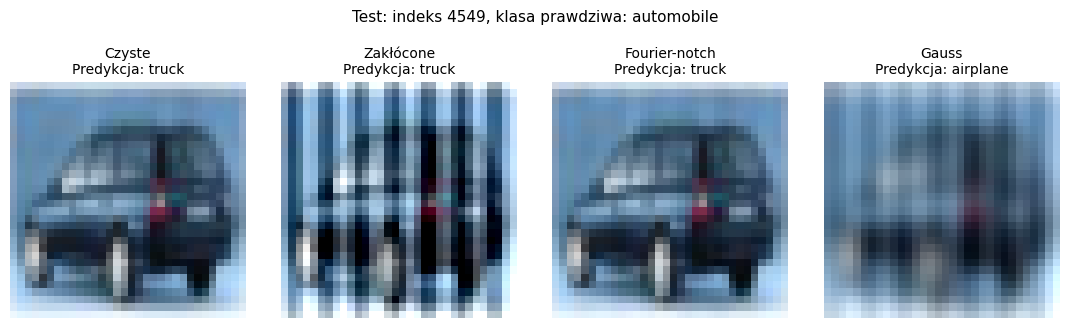

Zapisano konfigurację, kalibrację, wyniki, predykcje i wykresy w: C:\Users\mateu\Desktop\Studia\MRO\lab3\wyniki_lab3


In [14]:
i = EXAMPLE_INDEX
example_info = {'test_position': i, 'official_test_index': int(test_idx[i]),
                'true_class': classes[int(ytest[i])], 'variants': {}}
fig, axes = plt.subplots(1, 4, figsize=(11, 3.3))
for ax, (name, images) in zip(axes, variants.items()):
    pred_name = classes[int(test_predictions[name][i])]
    example_info['variants'][name] = {'prediction': pred_name,
                                     'mse': mse(images[i], Xtest[i])}
    ax.imshow(np.clip(images[i], 0, 1))
    ax.set_title(f'{name}\nPredykcja: {pred_name}', fontsize=10)
    ax.axis('off')
fig.suptitle(f'Test: indeks {int(test_idx[i])}, klasa prawdziwa: {classes[int(ytest[i])]}', fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig(RESULTS / 'porownanie_czterech.png', dpi=180, bbox_inches='tight')
plt.show()
experiment_summary = {
    'config': config, 'results': test_results, 'paired_changes': paired_changes,
    'noise_delta_vs_clean_pp': noise_delta_pp,
    'peak_evidence': peak_evidence,
    'fft': {'max_abs_reconstruction_error': fft_max_error, 'mse': fft_mse,
            'max_imaginary_error': fft_imag_error, 'mse_without_phase': no_phase_mse},
    'example': example_info, 'checkpoint_unchanged': checkpoint_hash_after == checkpoint_hash_before,
    'calibration_trials': calibration_trials,
}
(RESULTS / 'podsumowanie.json').write_text(
    json.dumps(experiment_summary, ensure_ascii=False, indent=2), encoding='utf-8',
)
print('Zapisano konfigurację, kalibrację, wyniki, predykcje i wykresy w:', RESULTS)

### Co pokazuje porównanie obrazów i metryk?

Na z góry ustalonym przykładzie testowym nr 4549 pasy po notch znikają, a kontury samochodu pozostają znacznie bliższe czystemu obrazowi niż po Gaussie. Gauss rozmywa kontury i nie usuwa całkowicie okresowego wzoru. To obserwacja tego przykładu, a nie miara całego zbioru.

Prawdziwa klasa to `automobile`. Dla czystego, zakłóconego i odfiltrowanego przez notch obrazu model przewiduje `truck`; po Gaussie `airplane`. Poprawa rekonstrukcji nie naprawia więc błędu obecnego już na czystym obrazie.

Na całym teście notch naprawia 172 błędy z wariantu zakłóconego, ale psuje 67 poprawnych odpowiedzi, co daje bilans +105/1000. Gauss naprawia 173 i psuje 182 (bilans -9/1000). To bezpośrednio wyjaśnia zmiany accuracy. Gauss obniża MSE z 0,031250 do 0,007085, lecz pogarsza accuracy o 0,90 p.p. Jest to konkretny kontrprzykład utożsamiania mniejszego błędu pikseli z lepszą klasyfikacją.

## Odpowiedzi i interpretacja oparta na wynikach

Odpowiedzi poniżej są wyliczane z faktycznie wykonanego przebiegu. Nie wnioskujemy o jakości klasyfikatora wyłącznie z wyglądu obrazu ani z najniższego MSE.

In [15]:
notch_row = by_variant['Fourier-notch']
gauss_row = by_variant['Gauss']
best_method = max([notch_row, gauss_row], key=lambda r: r['accuracy'])['variant']
ratio = min(p['power_ratio'] for p in peak_evidence)
notch_gain = notch_row['delta_accuracy_vs_noisy_pp']
gauss_gain = gauss_row['delta_accuracy_vs_noisy_pp']
display(Markdown(f'''
1. **Czy piki są zakłóceniem?** Wykryta para to {detected_pair}. W tych punktach
   moc zakłóconej kalibracji jest co najmniej {ratio:.1f} razy większa niż czystej.
   Taki wspólny przyrost w 300 obrazach wspiera interpretację jako zakłócenie.
   Samo maksimum widma bez porównania i wspólności między obrazami nie byłoby dowodem.
2. **Dlaczego usuwamy oba piki?** FFT rzeczywistego obrazu ma symetrię sprzężoną.
   Symetryczna maska zachowuje tę własność i daje rzeczywisty wynik IFFT.
   Usunięcie tylko jednej składowej pozostawiłoby część zakłócenia i wynik zespolony.
3. **Który filtr pomaga bardziej?** Wyższą accuracy uzyskał {best_method}.
   Notch zmienił accuracy o {notch_gain:+.2f} p.p., Gauss o {gauss_gain:+.2f} p.p.
   po zakłóceniu zmieniającym wynik o {noise_delta_pp:+.2f} p.p. względem czystych danych.
   MSE notch wynosi {notch_row['mse']:.6f}, a Gaussa {gauss_row['mse']:.6f}.
   MSE ocenia błędy pikseli, a accuracy decyzje sieci: poprawa obrazu nie gwarantuje
   poprawy rozpoznania. Gauss tłumi też krawędzie i tekstury, notch ograniczony wycinek widma.
4. **Co notch usuwa nieodwracalnie?** Również prawdziwe detale i tekstury obrazu,
   jeżeli mają energię w tych samych częstotliwościach. Ich oryginalnych współczynników
   nie odtworzymy z wyzerowanego widma; dlatego nawet usunięcie sinusoidy nie oznacza
   odzyskania dokładnie czystego obrazu. Przy 32 x 32 dostępne częstotliwości są rzadką siatką.
5. **Co przy innej częstotliwości dla każdego obrazu?** Uśredniona moc może mieć wiele
   słabszych maksimów lub szeroki pas. Jedna wspólna para i stała maska mogą zawieść;
   potrzebna byłaby detekcja na każdym obrazie lub model zmiennych częstotliwości,
   z parametrami ustalonymi poza testem.

**Granice wniosku:** to jeden model, 1000 obrazów i jeden demonstracyjny rodzaj zakłócenia.
Nie dowodzi to przewagi notch dla każdej częstotliwości i amplitudy. Nie przeprowadzano
testu istotności, więc różnicy nie nazywamy statystycznie istotną. Brak generatora
prowadzącego ogranicza zgodność eksperymentu z próbą przewidzianą na zajęciach.
'''))


1. **Czy piki są zakłóceniem?** Wykryta para to ((16, 9), (16, 23)). W tych punktach
   moc zakłóconej kalibracji jest co najmniej 333.3 razy większa niż czystej.
   Taki wspólny przyrost w 300 obrazach wspiera interpretację jako zakłócenie.
   Samo maksimum widma bez porównania i wspólności między obrazami nie byłoby dowodem.
2. **Dlaczego usuwamy oba piki?** FFT rzeczywistego obrazu ma symetrię sprzężoną.
   Symetryczna maska zachowuje tę własność i daje rzeczywisty wynik IFFT.
   Usunięcie tylko jednej składowej pozostawiłoby część zakłócenia i wynik zespolony.
3. **Który filtr pomaga bardziej?** Wyższą accuracy uzyskał Fourier-notch.
   Notch zmienił accuracy o +10.50 p.p., Gauss o -0.90 p.p.
   po zakłóceniu zmieniającym wynik o -10.70 p.p. względem czystych danych.
   MSE notch wynosi 0.000087, a Gaussa 0.007085.
   MSE ocenia błędy pikseli, a accuracy decyzje sieci: poprawa obrazu nie gwarantuje
   poprawy rozpoznania. Gauss tłumi też krawędzie i tekstury, notch ograniczony wycinek widma.
4. **Co notch usuwa nieodwracalnie?** Również prawdziwe detale i tekstury obrazu,
   jeżeli mają energię w tych samych częstotliwościach. Ich oryginalnych współczynników
   nie odtworzymy z wyzerowanego widma; dlatego nawet usunięcie sinusoidy nie oznacza
   odzyskania dokładnie czystego obrazu. Przy 32 x 32 dostępne częstotliwości są rzadką siatką.
5. **Co przy innej częstotliwości dla każdego obrazu?** Uśredniona moc może mieć wiele
   słabszych maksimów lub szeroki pas. Jedna wspólna para i stała maska mogą zawieść;
   potrzebna byłaby detekcja na każdym obrazie lub model zmiennych częstotliwości,
   z parametrami ustalonymi poza testem.

**Granice wniosku:** to jeden model, 1000 obrazów i jeden demonstracyjny rodzaj zakłócenia.
Nie dowodzi to przewagi notch dla każdej częstotliwości i amplitudy. Nie przeprowadzano
testu istotności, więc różnicy nie nazywamy statystycznie istotną. Brak generatora
prowadzącego ogranicza zgodność eksperymentu z próbą przewidzianą na zajęciach.


## Wykorzystanie modelu językowego i sprawdzenie odpowiedzi

Korzystano z Codex przy implementacji, kontroli obliczeń i przygotowaniu raportu. Przykładowe pytania i sposób weryfikacji:

1. „Jak wykryć parę sprzężonych pików po fftshift, z pominięciem DC?” - test `detect_pair` na sztucznym widmie ze znaną parą oraz silniejszym DC; kontrola symetrii współrzędnych.
2. „Jak filtrować RGB bez mieszania obrazów i kanałów?” - FFT wyłącznie po osiach przestrzennych, sigma Gaussa równa zero na osi obrazów i kanałów; sprawdzenie rozmiarów oraz części urojonej IFFT.
3. „Jak porównać filtry bez dobierania parametrów na teście?” - zapis konfiguracji przed ewaluacją testu, wybór według MSE kalibracji; bilans naprawionych i zepsutych predykcji sprawdzony z różnicą accuracy; kontrola niezmienności pliku wag.

Dokładne wartości do raportu pochodzą z `wyniki_lab3/podsumowanie.json`, a nie z szacunków modelu językowego.